# Semaine 2 — Feature Engineering & Baseline
### Predictive Maintenance for Sensor Data — NASA C-MAPSS (FD001)

**Objectifs de ce notebook** (suite directe de l'EDA de la semaine 1) :
1. Construire la target RUL (avec plafonnement piecewise-linear).
2. Exclure les capteurs constants identifiés en semaine 1.
3. Feature engineering : fenêtres glissantes (rolling mean/std) par moteur.
4. PCA en option, justifiée par la variance expliquée.
5. Mettre en place une méthodologie de split **sans fuite de données** (par unité, temporelle).
6. Entraîner et évaluer une baseline (régression linéaire) avec évaluation **par unité**, pas par ligne.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42


## 1. Chargement des données

In [2]:
index_names = ["unit_number", "time_in_cycles"]
setting_names = [f"op_setting_{i}" for i in range(1, 4)]
sensor_names = [f"sensor_{i}" for i in range(1, 22)]
col_names = index_names + setting_names + sensor_names

train = pd.read_csv("data/train_FD001.txt", sep=r"\s+", header=None, names=col_names)
test = pd.read_csv("data/test_FD001.txt", sep=r"\s+", header=None, names=col_names)
rul_test = pd.read_csv("data/RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL_true"])
rul_test["unit_number"] = rul_test.index + 1  # RUL_FD001 est ordonné par unit_number

print("Train:", train.shape, "| Test:", test.shape)


Train: (20631, 26) | Test: (13096, 26)


## 2. Target : RUL avec plafonnement piecewise-linear

Rappel de la semaine 1 : la RUL "vraie" décroît linéairement du premier au dernier cycle, mais en tout début
de vie le moteur ne montre quasiment aucun signe de dégradation. La pratique standard sur C-MAPSS (utilisée
dans la littérature depuis Heimes 2008) est de **plafonner** la RUL à une valeur max `RUL_CAP` : le modèle
n'a pas besoin d'apprendre à distinguer "il reste 250 cycles" de "il reste 400 cycles", ces deux cas sont
équivalents en pratique ("tout va bien pour l'instant").

On choisit `RUL_CAP = 125`, valeur standard dans la littérature C-MAPSS — **à justifier toi-même** en
comparant à la distribution des durées de vie trouvée en semaine 1 (garde une trace de ce raisonnement dans
ton rapport, ne prends pas cette valeur pour acquise sans la vérifier sur tes propres chiffres).


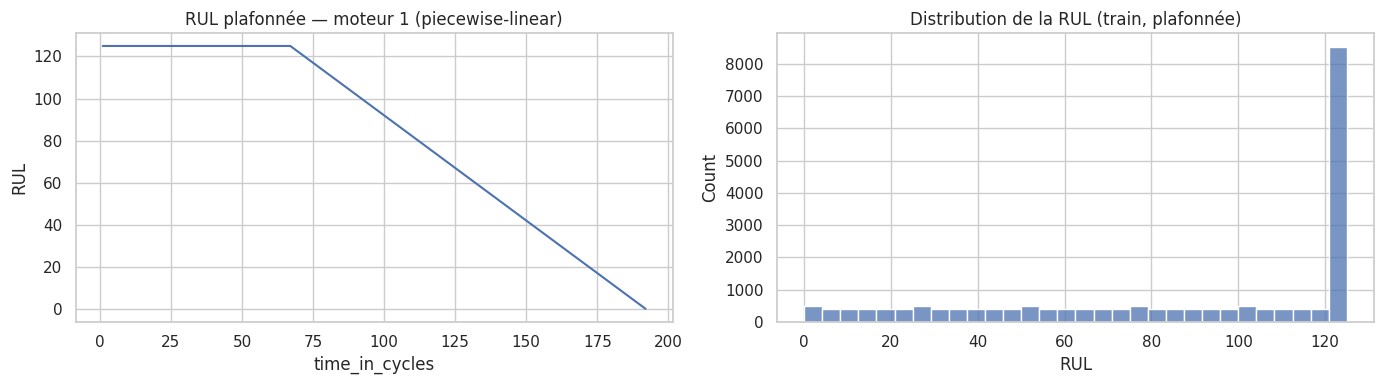

In [3]:
RUL_CAP = 125

def add_rul_train(df):
    max_cycle = df.groupby("unit_number")["time_in_cycles"].transform("max")
    df = df.copy()
    df["RUL"] = (max_cycle - df["time_in_cycles"]).clip(upper=RUL_CAP)
    return df

train = add_rul_train(train)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
train[train["unit_number"] == 1].plot(x="time_in_cycles", y="RUL", ax=ax[0], legend=False)
ax[0].set_title("RUL plafonnée — moteur 1 (piecewise-linear)")
ax[0].set_ylabel("RUL")

sns.histplot(train["RUL"], bins=30, ax=ax[1])
ax[1].set_title("Distribution de la RUL (train, plafonnée)")
plt.tight_layout()
plt.show()


## 3. Exclusion des capteurs constants (résultat de la semaine 1)

On recalcule ici pour que ce notebook soit autonome et reproductible, mais la logique est identique à
l'EDA de la semaine 1.


In [4]:
sensor_std = train[sensor_names].std()
constant_sensors = sensor_std[sensor_std < 1e-4].index.tolist()
useful_sensors = [s for s in sensor_names if s not in constant_sensors]

print("Capteurs exclus (constants) :", constant_sensors)
print(f"{len(useful_sensors)} capteurs conservés sur {len(sensor_names)}.")


Capteurs exclus (constants) : ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
15 capteurs conservés sur 21.


## 4. Feature engineering — fenêtres glissantes (rolling)

Pour chaque capteur retenu, on calcule une moyenne et un écart-type glissants sur une fenêtre de
`WINDOW` cycles, **par moteur** (`groupby("unit_number")`) pour ne jamais mélanger les trajectoires de deux
moteurs différents, et **sans jamais regarder le futur** (`rolling` en pandas est causal par construction :
la valeur au temps t n'utilise que les valeurs ≤ t).

⚠️ **Piège de fuite de données à vérifier explicitement** : si tu ajoutes d'autres features plus tard
(ex. `shift(-1)`, différences avec un cycle futur), assure-toi toujours qu'elles ne regardent que le passé.


In [5]:
WINDOW = 5

def add_rolling_features(df, sensors, window):
    df = df.sort_values(["unit_number", "time_in_cycles"]).copy()
    grouped = df.groupby("unit_number")[sensors]

    roll_mean = grouped.rolling(window=window, min_periods=1).mean().reset_index(level=0, drop=True)
    roll_std = grouped.rolling(window=window, min_periods=1).std().fillna(0).reset_index(level=0, drop=True)

    roll_mean.columns = [f"{c}_roll_mean{window}" for c in roll_mean.columns]
    roll_std.columns = [f"{c}_roll_std{window}" for c in roll_std.columns]

    return pd.concat([df, roll_mean, roll_std], axis=1)

train_feat = add_rolling_features(train, useful_sensors, WINDOW)
test_feat = add_rolling_features(test, useful_sensors, WINDOW)

feature_cols = useful_sensors + [f"{s}_roll_mean{WINDOW}" for s in useful_sensors] + [f"{s}_roll_std{WINDOW}" for s in useful_sensors]
print(f"{len(feature_cols)} features au total (bruts + rolling mean/std, fenêtre={WINDOW}).")
train_feat[["unit_number", "time_in_cycles"] + feature_cols[:4]].head(8)


45 features au total (bruts + rolling mean/std, fenêtre=5).


,unit_number,time_in_cycles,sensor_2,sensor_3,sensor_4,sensor_6
0,1,1,641.82,1589.70,1400.60,21.61
1,1,2,642.15,1591.82,1403.14,21.61
2,1,3,642.35,1587.99,1404.20,21.61
3,1,4,642.35,1582.79,1401.87,21.61
4,1,5,642.37,1582.85,1406.22,21.61
5,1,6,642.10,1584.47,1398.37,21.61
6,1,7,642.48,1592.32,1397.77,21.61
7,1,8,642.56,1582.96,1400.97,21.61


**Vérification visuelle** : les rolling features doivent lisser le bruit par rapport au signal brut,
tout en gardant la tendance de dégradation.


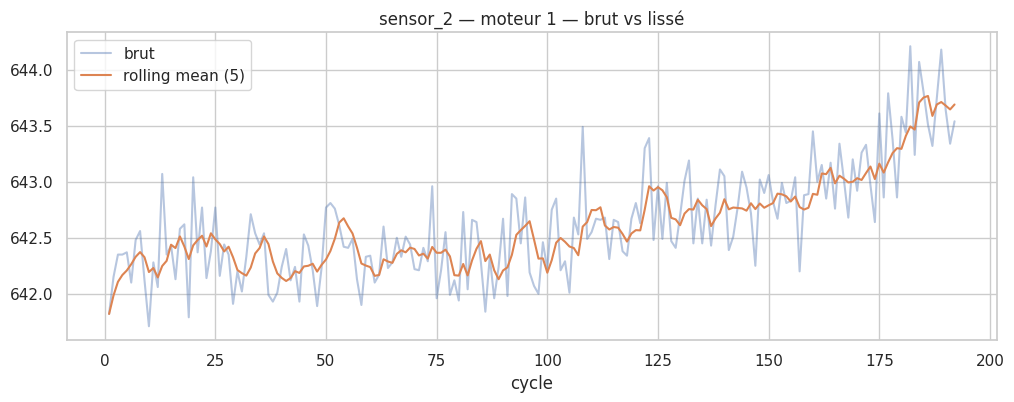

In [6]:
sensor_example = useful_sensors[0]
unit_example = 1
unit_data = train_feat[train_feat["unit_number"] == unit_example]

plt.figure(figsize=(12, 4))
plt.plot(unit_data["time_in_cycles"], unit_data[sensor_example], alpha=0.4, label="brut")
plt.plot(unit_data["time_in_cycles"], unit_data[f"{sensor_example}_roll_mean{WINDOW}"], label=f"rolling mean ({WINDOW})")
plt.title(f"{sensor_example} — moteur {unit_example} — brut vs lissé")
plt.xlabel("cycle")
plt.legend()
plt.show()


## 5. PCA — option, à justifier par la variance expliquée

On ne fait PAS de PCA "par défaut". On regarde d'abord combien de composantes seraient nécessaires pour
expliquer, disons, 95% de la variance. Si ça prend presque autant de composantes que de features d'origine,
la PCA n'apporte pas grand-chose ici et ce n'est pas la peine de la garder dans le pipeline final.


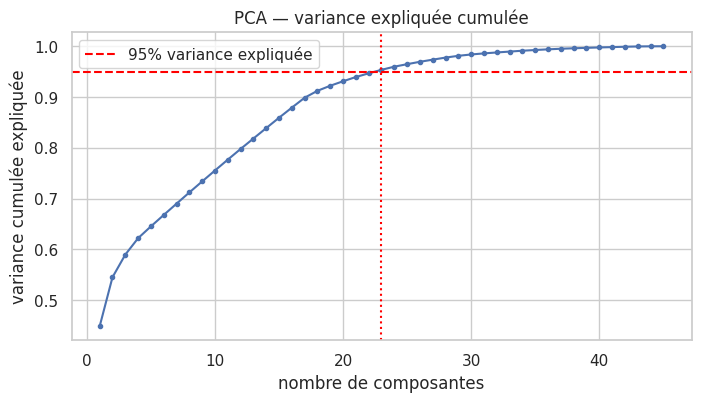

23 composantes suffisent pour expliquer 95% de la variance (sur 45 features d'origine).


In [7]:
scaler_pca = StandardScaler()
X_scaled_for_pca = scaler_pca.fit_transform(train_feat[feature_cols])

pca = PCA(random_state=RANDOM_STATE)
pca.fit(X_scaled_for_pca)

cumvar = np.cumsum(pca.explained_variance_ratio_)
n_components_95 = np.argmax(cumvar >= 0.95) + 1

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumvar) + 1), cumvar, marker=".")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance expliquée")
plt.axvline(n_components_95, color="red", linestyle=":")
plt.xlabel("nombre de composantes")
plt.ylabel("variance cumulée expliquée")
plt.legend()
plt.title("PCA — variance expliquée cumulée")
plt.show()

print(f"{n_components_95} composantes suffisent pour expliquer 95% de la variance "
      f"(sur {len(feature_cols)} features d'origine).")


**Décision à documenter dans le rapport** : si `n_components_95` est nettement plus petit que le
nombre de features d'origine (ex: 2-3x moins), la PCA est justifiée pour réduire la dimensionnalité avant un
modèle linéaire. Si elle est proche du nombre total de features, ça veut dire que les features sont déjà peu
redondantes et la PCA n'apporterait qu'une perte d'interprétabilité pour peu de gain. **Ce notebook n'active
pas la PCA dans le pipeline final ci-dessous** — active-la toi-même dans le pipeline (`Pipeline` scikit-learn)
si tes résultats la justifient.


## 6. Méthodologie de split — SANS fuite de données

Deux niveaux de split à bien distinguer :

1. **Train vs Test officiel du challenge** (`train_FD001.txt` vs `test_FD001.txt`) : déjà séparés par
   construction — ce sont des moteurs complètement différents. On garde ce split pour l'évaluation finale.
2. **Train vs Validation** (pour choisir les hyperparamètres pendant le développement) : on ne fait **jamais**
   un split aléatoire ligne par ligne (une ligne au cycle t d'un moteur X finirait en train et une ligne au
   cycle t+1 du même moteur en validation → fuite). On split **par unité de moteur** avec `GroupKFold`.


In [8]:
gkf = GroupKFold(n_splits=5)
groups = train_feat["unit_number"]
split = next(gkf.split(train_feat[feature_cols], train_feat["RUL"], groups))
train_idx, val_idx = split

X_train, y_train = train_feat.iloc[train_idx][feature_cols], train_feat.iloc[train_idx]["RUL"]
X_val, y_val = train_feat.iloc[val_idx][feature_cols], train_feat.iloc[val_idx]["RUL"]

train_units = set(train_feat.iloc[train_idx]["unit_number"])
val_units = set(train_feat.iloc[val_idx]["unit_number"])
print("Chevauchement d'unités train/val :", train_units & val_units, "(doit être vide !)")
print(f"Train: {X_train.shape[0]} lignes / {len(train_units)} moteurs")
print(f"Val  : {X_val.shape[0]} lignes / {len(val_units)} moteurs")


Chevauchement d'unités train/val : set() (doit être vide !)
Train: 16511 lignes / 80 moteurs
Val  : 4120 lignes / 20 moteurs


## 7. Baseline — Régression linéaire

On entraîne une régression linéaire simple sur les features (brutes + rolling), avec un scaling fit
**uniquement sur le train** (jamais sur val/test, pour éviter toute fuite d'information sur la distribution).


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

baseline = LinearRegression()
baseline.fit(X_train_scaled, y_train)

pred_val = baseline.predict(X_val_scaled)
pred_val = np.clip(pred_val, 0, None)  # la RUL ne peut pas être négative

rmse = root_mean_squared_error(y_val, pred_val)
mae = mean_absolute_error(y_val, pred_val)
print(f"Validation (par ligne) — RMSE: {rmse:.2f} | MAE: {mae:.2f}")


Validation (par ligne) — RMSE: 22.16 | MAE: 17.97


⚠️ **Ce score ci-dessus est calculé par ligne, ce n'est PAS l'évaluation officielle du problème.**
Le brief demande explicitement une **évaluation par unité**, pas par ligne. En pratique, ce qui compte
vraiment c'est : à la toute fin de la trajectoire disponible pour un moteur, est-ce que le modèle prédit
correctement la RUL restante ? On calcule donc aussi le score sur le **dernier cycle de chaque moteur**.


In [10]:
val_df = train_feat.iloc[val_idx].copy()
val_df["pred"] = pred_val

last_cycle_per_unit = val_df.loc[val_df.groupby("unit_number")["time_in_cycles"].idxmax()]

rmse_last = root_mean_squared_error(last_cycle_per_unit["RUL"], last_cycle_per_unit["pred"])
mae_last = mean_absolute_error(last_cycle_per_unit["RUL"], last_cycle_per_unit["pred"])
print(f"Validation (dernier cycle par moteur, {len(last_cycle_per_unit)} moteurs) — "
      f"RMSE: {rmse_last:.2f} | MAE: {mae_last:.2f}")


Validation (dernier cycle par moteur, 20 moteurs) — RMSE: 6.18 | MAE: 3.44


## 8. Évaluation sur le vrai test set (protocole officiel C-MAPSS)

Le test set contient des trajectoires **tronquées** (le moteur n'est pas allé jusqu'à la panne dans les
données fournies). La RUL vraie au dernier cycle disponible est donnée séparément dans `RUL_FD001.txt`.
L'évaluation officielle se fait donc : pour chaque moteur du test, prédire la RUL sur son dernier cycle
enregistré, et comparer à `RUL_FD001.txt`.


TEST officiel (dernier cycle, 100 moteurs) — RMSE: 21.84 | MAE: 17.50


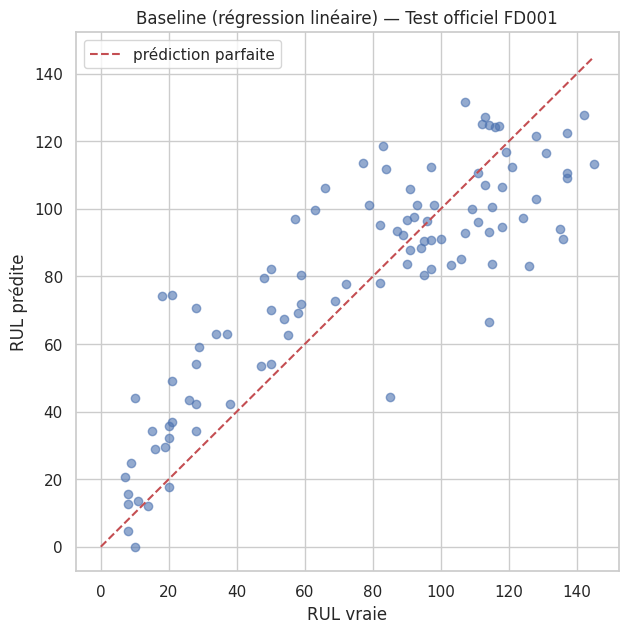

In [11]:
last_test = test_feat.loc[test_feat.groupby("unit_number")["time_in_cycles"].idxmax()].copy()
last_test = last_test.merge(rul_test, on="unit_number")

X_test_scaled = scaler.transform(last_test[feature_cols])
last_test["pred"] = np.clip(baseline.predict(X_test_scaled), 0, None)

rmse_test = root_mean_squared_error(last_test["RUL_true"], last_test["pred"])
mae_test = mean_absolute_error(last_test["RUL_true"], last_test["pred"])
print(f"TEST officiel (dernier cycle, {len(last_test)} moteurs) — RMSE: {rmse_test:.2f} | MAE: {mae_test:.2f}")

plt.figure(figsize=(7, 7))
plt.scatter(last_test["RUL_true"], last_test["pred"], alpha=0.6)
lims = [0, max(last_test["RUL_true"].max(), last_test["pred"].max())]
plt.plot(lims, lims, "r--", label="prédiction parfaite")
plt.xlabel("RUL vraie")
plt.ylabel("RUL prédite")
plt.legend()
plt.title("Baseline (régression linéaire) — Test officiel FD001")
plt.show()


## 9. Baseline naïve de comparaison (sanity check)

Toujours comparer son modèle à une baseline triviale — ici, prédire simplement la RUL moyenne du train pour
tous les moteurs de test. Si la régression linéaire ne fait pas significativement mieux que ça, c'est un
signal qu'il y a un problème (features non informatives, bug de pipeline...).


In [12]:
naive_pred = np.full(len(last_test), y_train.mean())
rmse_naive = root_mean_squared_error(last_test["RUL_true"], naive_pred)
mae_naive = mean_absolute_error(last_test["RUL_true"], naive_pred)

print(f"Baseline naïve (moyenne du train) — RMSE: {rmse_naive:.2f} | MAE: {mae_naive:.2f}")
print(f"Régression linéaire              — RMSE: {rmse_test:.2f} | MAE: {mae_test:.2f}")
print(f"Gain relatif sur le RMSE : {(1 - rmse_test / rmse_naive) * 100:.1f}%")


Baseline naïve (moyenne du train) — RMSE: 43.07 | MAE: 35.90
Régression linéaire              — RMSE: 21.84 | MAE: 17.50
Gain relatif sur le RMSE : 49.3%


## 10. Sauvegarde des features (pour la semaine 3 — XGBoost/LightGBM)

On sauvegarde les datasets enrichis pour ne pas refaire ce travail dans le notebook suivant.


In [13]:
train_feat.to_parquet("data/train_features.parquet", index=False)
test_feat.to_parquet("data/test_features.parquet", index=False)
rul_test.to_parquet("data/rul_test.parquet", index=False)

print("Fichiers sauvegardés dans data/ :")
print("  - train_features.parquet")
print("  - test_features.parquet")
print("  - rul_test.parquet")


Fichiers sauvegardés dans data/ :
  - train_features.parquet
  - test_features.parquet
  - rul_test.parquet


## 11. Synthèse — à compléter avec tes propres résultats

- **Capteurs conservés** : voir `useful_sensors` (section 3).
- **Fenêtre de rolling retenue** : `WINDOW = 5` — à faire varier toi-même (3, 10, 20 cycles) et comparer
  l'effet sur le RMSE de validation avant de figer ce choix dans le rapport.
- **PCA** : décision (activée ou non) à documenter à partir de la courbe de variance expliquée (section 5).
- **RUL_CAP = 125** : à confronter à la distribution des durées de vie de la semaine 1.
- **Score baseline (test officiel)** : RMSE/MAE relevés en section 8, à comparer à la baseline naïve
  (section 9) — le gain relatif est le chiffre à retenir pour ton rapport, pas juste le RMSE brut.

**Prochaine étape (semaine 3)** : XGBoost/LightGBM sur ces mêmes features (`train_features.parquet`), avec
tuning d'hyperparamètres via la `GroupKFold` définie en section 6, et une analyse d'erreurs par unité.
